# Insight Bisnis: Apa yang Sebenarnya Terjadi di Pasar Mobil Bekas?

Notebook ini menjawab pertanyaan yang lebih berguna bagi penjual, pembeli, maupun dealer: **apa yang menentukan harga, dan seberapa besar?**

**Pertanyaan bisnis:**
1. Seberapa cepat harga mobil turun seiring umur, dan kapan penurunannya paling curam?
2. Model dan merek mana yang harganya paling tahan, dan mana yang paling cepat turun (dalam rupiah)?
3. Seberapa besar pengaruh kilometer dibanding umur?
4. Berapa "premium" yang dibayar untuk transmisi Automatic, diesel, dan hybrid?
5. Apakah mobil listrik bekas turun harga lebih cepat daripada bensin?
6. Apakah harga berbeda antar platform dan antar waktu, dan di mana harga paling beragam?

## Load Data

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression

from clean_zenodo import bersihkan
from clean_carsome import muat_carsome

PATH_ZENODO = "../data/dataset_raw_29747.csv"
PATH_CARSOME = "../data/used_car.csv"

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
UNGU, CYAN, PINK, ABU = "#8B5CF6", "#22D3EE", "#F472B6", "#9AA4B2"

In [2]:
zen, _ = bersihkan(PATH_ZENODO)
carsome = muat_carsome(PATH_CARSOME, zen)
df = pd.concat([zen, carsome], ignore_index=True)
df = df[df["bahan_bakar"].notna()].copy()

TAHUN_DATA = {"OLX": 2026, "Mobil123": 2026, "Carsome": 2023} #(tahun pengambilan data)
df["umur"] = (df["sumber"].map(TAHUN_DATA) - df["tahun"]).clip(lower=0)
df["model_lengkap"] = df["merek"] + " " + df["model"].astype(str)
df["log_harga"] = np.log(df["harga"])

pasar = df[df["sumber"] != "Carsome"].copy()#(iklan marketplace 2025-2026)
jumlah = pasar["model_lengkap"].value_counts()
MODEL_POPULER = set(jumlah[jumlah >= 100].index)#(model dengan >= 100 iklan)

print("Total iklan:", len(df), "| iklan marketplace:", len(pasar), "| model populer:", len(MODEL_POPULER))
print(df["sumber"].value_counts().to_string())

Total iklan: 19493 | iklan marketplace: 18884 | model populer: 48
sumber
OLX         13252
Mobil123     5632
Carsome       609


In [3]:
def persen(b):
    return (np.exp(b) - 1) * 100


def regresi(d, ekstra=()):
    umur_k = d["umur"].clip(lower=1).astype(int)
    X = pd.concat([pd.get_dummies(d["model_lengkap"]),
                   pd.get_dummies(umur_k, prefix="umur").drop(columns="umur_1", errors="ignore"),
                   d[list(ekstra)]], axis=1).astype(float)
    m = LinearRegression(fit_intercept=False).fit(X, d["log_harga"])
    return pd.Series(m.coef_, index=X.columns), (d["log_harga"] - m.predict(X))

## Seberapa cepat harga turun seiring umur?
untuk 48 model populer (≥ 100 iklan), harga dibandingkan antar umur *dalam model yang sama*, dengan umur 1 tahun sebagai pembanding (= 100).

In [4]:
d1 = pasar[pasar["model_lengkap"].isin(MODEL_POPULER) & (pasar["umur"] <= 15) & (pasar["bahan_bakar"] != "Listrik")]
koef, _ = regresi(d1)
retensi = pd.Series({1: 1.0, **{int(k.split("_")[1]): float(np.exp(v)) for k, v in koef.items() if k.startswith("umur_")}}).sort_index()
turun_tahunan = (retensi / retensi.shift(1) - 1) * 100

tabel_retensi = pd.DataFrame({
    "harga relatif (umur 1 = 100)": retensi * 100,
    "perubahan vs tahun sebelumnya (%)": turun_tahunan,
    "jumlah iklan": d1["umur"].clip(lower=1).astype(int).value_counts().sort_index(),
})
tabel_retensi.round(1)

,harga relatif (umur 1 = 100),perubahan vs tahun sebelumnya (%),jumlah iklan
1,100.0,NaN,268
2,96.1,-3.9,919
3,89.2,-7.2,1587
4,82.7,-7.2,2066
5,75.8,-8.4,1662
6,70.8,-6.6,914
7,66.9,-5.4,1571
8,60.9,-9.0,1478
9,57.3,-6.0,1327
10,52.3,-8.7,1057


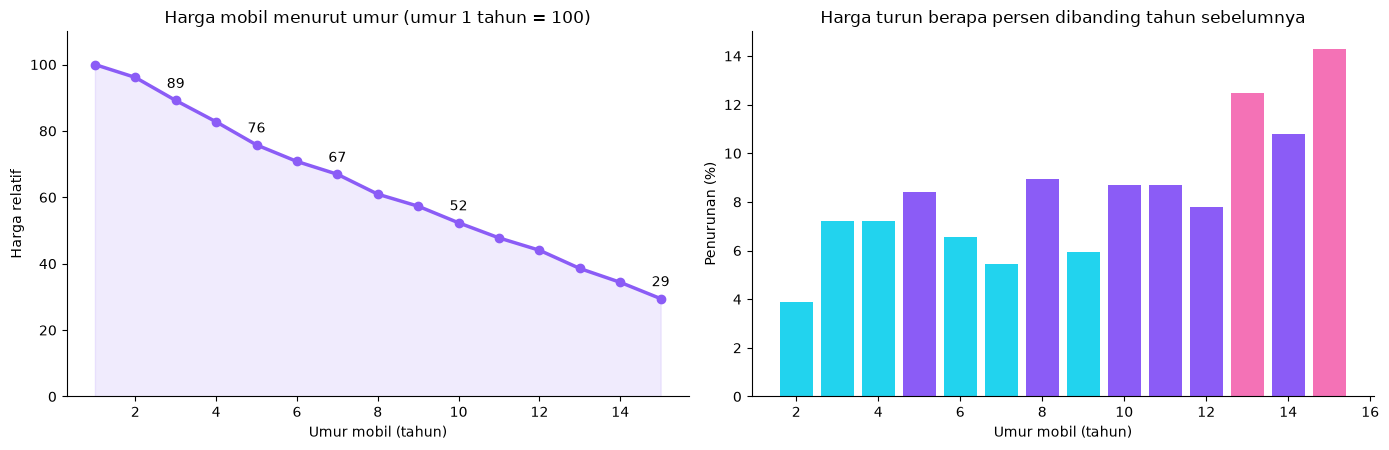

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(retensi.index, retensi * 100, marker="o", color=UNGU, lw=2.5)
ax[0].fill_between(retensi.index, retensi * 100, color=UNGU, alpha=0.12)
for u in (3, 5, 7, 10, 15):
    ax[0].annotate(f"{retensi[u] * 100:.0f}", (u, retensi[u] * 100), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=10)
ax[0].set_title("Harga mobil menurut umur (umur 1 tahun = 100)")
ax[0].set_xlabel("Umur mobil (tahun)")
ax[0].set_ylabel("Harga relatif")
ax[0].set_ylim(0, 110)

warna = [CYAN if v < 7.5 else UNGU if v < 11 else PINK for v in -turun_tahunan.iloc[1:]]
ax[1].bar(turun_tahunan.index[1:], -turun_tahunan.iloc[1:], color=warna)
ax[1].set_title("Harga turun berapa persen dibanding tahun sebelumnya")
ax[1].set_xlabel("Umur mobil (tahun)")
ax[1].set_ylabel("Penurunan (%)")
plt.tight_layout()
plt.show()

**Temuan:**
- Dibanding mobil berumur 1 tahun, harga mobil sepantaran turun menjadi **±89 pada umur 3, ±76 pada umur 5, ±67 pada umur 7, ±52 pada umur 10, dan ±29 pada umur 15**.
- Penurunan tahun pertama kecil (±4%), lalu stabil di kisaran **6-9% per tahun** sampai umur 12, dan **makin curam setelah umur 12 (11-14% per tahun)**, walau angka di umur tua kurang stabil karena iklannya lebih sedikit.
- Mobil yang ditahan dari umur 5 sampai umur 10 kehilangan sekitar **31% dari nilainya** (76 menjadi 52).

**Artinya:** untuk **pembeli**, umur 3-5 tahun adalah titik tengah yang masuk akal (harga sudah turun 11-24% dari umur 1 tahun, tapi mobil masih relatif baru). Untuk **penjual**, menahan mobil melewati umur 12 tahun mempercepat kehilangan nilai.

*Catatan metode:* ini membandingkan mobil berbeda pada umur berbeda di waktu yang sama (potret 2025-2026), bukan melacak satu mobil dari tahun ke tahun.

## 3. Model dan merek mana yang harganya paling tahan?
**Cara dihitung:** untuk tiap model dengan data memadai, laju penurunan harga per tahun dihitung pada **rentang umur yang sama (1-8 tahun)** supaya perbandingannya adil. Lalu diterjemahkan ke rupiah per tahun pada umur 5 tahun.

In [6]:
JENDELA = (1, 8)# semua model dibandingkan pada rentang umur yang sama
w2 = pasar[pasar["model_lengkap"].isin(MODEL_POPULER) & pasar["umur"].between(*JENDELA) & (pasar["bahan_bakar"] != "Listrik")]
baris = []
for nama, g in w2.groupby("model_lengkap"):
    if len(g) < 80 or g["umur"].nunique() < 5:
        continue
    b, a = np.polyfit(g["umur"], g["log_harga"], 1)
    harga5 = np.exp(a + b * 5)
    baris.append({"model": nama, "merek": g["merek"].iloc[0], "iklan": len(g),
                  "turun_%_per_tahun": (1 - np.exp(b)) * 100,
                  "harga_umur5_juta": harga5 / 1e6,
                  "turun_juta_per_tahun": harga5 * (1 - np.exp(b)) / 1e6})
laju = pd.DataFrame(baris).sort_values("turun_%_per_tahun").reset_index(drop=True)

print(f"{len(laju)} model dibandingkan | median laju penurunan: {laju['turun_%_per_tahun'].median():.1f}% per tahun\n")
print("10 model yang harganya paling TAHAN:")
print(laju.head(10)[["model", "iklan", "turun_%_per_tahun"]].to_string(index=False))
print("\n10 model yang harganya paling CEPAT TURUN:")
print(laju.tail(10)[["model", "iklan", "turun_%_per_tahun"]].to_string(index=False))

40 model dibandingkan | median laju penurunan: 6.7% per tahun

10 model yang harganya paling TAHAN:
            model  iklan  turun_%_per_tahun
   Daihatsu Rocky    202                2.0
     Suzuki Jimny    131                2.3
     Toyota Raize    172                2.4
Daihatsu Gran max     90                3.0
   Daihatsu Sigra    584                3.4
    Honda Mobilio    186                3.4
  Daihatsu Terios    344                3.8
    Daihatsu Ayla    560                4.0
       Honda Brio    442                4.3
       Suzuki XL7    366                4.5

10 model yang harganya paling CEPAT TURUN:
                  model  iklan  turun_%_per_tahun
         Toyota Alphard    188               11.1
             Honda CR-V    519               11.2
  Mercedes-Benz C-Class    343               11.3
  Mercedes-Benz E-Class    216               11.5
Mercedes-Benz GLA-Class     88               11.9
  Mercedes-Benz S-Class     85               12.5
           Toyota Camr

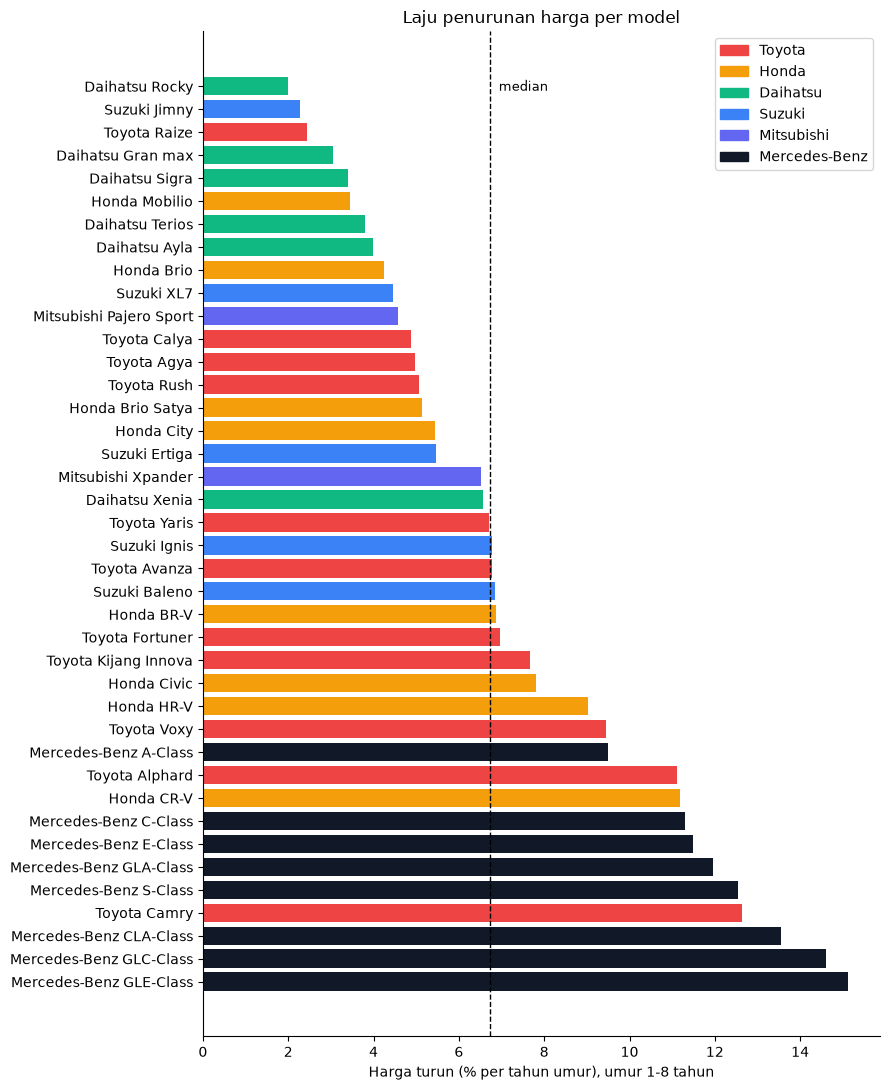

Median laju penurunan per merek (dari model-model di atas):


,jumlah_model,median
merek,,
Daihatsu,6,3.6
Suzuki,5,5.5
Mitsubishi,2,5.5
Honda,8,6.1
Toyota,11,6.8
Mercedes-Benz,8,12.2


In [7]:
WARNA_MEREK = {"Toyota": "#EF4444", "Honda": "#F59E0B", "Daihatsu": "#10B981", "Suzuki": "#3B82F6",
               "Mitsubishi": "#6366F1", "Mercedes-Benz": "#111827"}
urut = laju.sort_values("turun_%_per_tahun", ascending=True)
fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(urut["model"], urut["turun_%_per_tahun"], color=[WARNA_MEREK.get(m, ABU) for m in urut["merek"]])
ax.axvline(laju["turun_%_per_tahun"].median(), color="k", ls="--", lw=1)
ax.text(laju["turun_%_per_tahun"].median() + 0.2, 0.2, "median", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Harga turun (% per tahun umur), umur 1-8 tahun")
ax.set_title("Laju penurunan harga per model")
ax.legend(handles=[Patch(color=c, label=m) for m, c in WARNA_MEREK.items()], loc="upper right")
plt.tight_layout()
plt.show()

print("Median laju penurunan per merek (dari model-model di atas):")
laju.groupby("merek")["turun_%_per_tahun"].agg(jumlah_model="count", median="median").sort_values("median").round(1)

In [8]:
contoh = ["Daihatsu Sigra", "Toyota Avanza", "Honda Brio", "Toyota Kijang Innova", "Honda HR-V",
          "Toyota Fortuner", "Honda CR-V", "Mercedes-Benz C-Class", "Mercedes-Benz E-Class"]
rp = laju[laju["model"].isin(contoh)].set_index("model").loc[[c for c in contoh if c in set(laju["model"])]]
rp[["harga_umur5_juta", "turun_%_per_tahun", "turun_juta_per_tahun"]].round(1)

,harga_umur5_juta,turun_%_per_tahun,turun_juta_per_tahun
model,,,
Daihatsu Sigra,112.0,3.4,3.8
Toyota Avanza,180.7,6.8,12.2
Honda Brio,152.6,4.3,6.5
Toyota Kijang Innova,319.8,7.7,24.5
Honda HR-V,254.0,9.0,22.9
Toyota Fortuner,427.8,7.0,29.8
Honda CR-V,383.4,11.2,42.9
Mercedes-Benz C-Class,609.1,11.3,68.9
Mercedes-Benz E-Class,725.9,11.5,83.3


**Temuan:**
- Laju penurunan **median antar model: ±6,7% per tahun.**
- **Paling tahan harga:** Daihatsu Rocky (2,0%), Suzuki Jimny (2,3%), Toyota Raize (2,4%), lalu Daihatsu Gran Max, Sigra, Honda Mobilio, Daihatsu Terios dan Ayla, Honda Brio (3,0-4,3%). *Rocky, Jimny, dan Raize adalah model baru dengan umur data pendek (di bawah ±6 tahun) dan permintaan tinggi, jadi baca sebagai "sejauh ini".*
- **Paling cepat turun:** semua kelas Mercedes-Benz (E, C, GLA, S, CLA, GLC, GLE: 11-15% per tahun), Toyota Camry (12,6%), Honda CR-V (11,2%), dan Toyota Alphard (11,1%).
- Per merek (median laju model): Daihatsu ±3,6%, Suzuki dan Mitsubishi ±5,5%, Honda ±6,1%, Toyota ±6,8%, **Mercedes-Benz ±12,2%** (sekitar dua kali Toyota).
- **Dalam rupiah (umur 5 tahun):** Daihatsu Sigra kehilangan ±Rp 4 juta per tahun, Honda Brio ±Rp 6,5 juta, Toyota Avanza ±Rp 12 juta, Innova ±Rp 24 juta, Fortuner ±Rp 30 juta, Honda CR-V ±Rp 43 juta, **Mercedes C-Class ±Rp 69 juta**, dan E-Class ±Rp 83 juta. Penyusutan C-Class per tahun sekitar **5-6 kali** Avanza.

**Artinya:** untuk pembeli yang ingin meminimalkan biaya penyusutan, model Daihatsu/Honda/Suzuki kelas kecil-menengah jauh lebih aman. Mobil mewah punya "biaya kepemilikan" penyusutan yang besar dalam rupiah, bahkan ketika persentasenya terlihat biasa.

## 4. Umur atau kilometer: mana yang lebih menentukan harga?
**cara hitung** pengaruh +10.000 km terhadap harga, dengan dan tanpa mengontrol umur. Lalu pada mobil berumur 4-6 tahun, harga dibandingkan antar kelompok kilometer.

In [9]:
k = pasar[pasar["model_lengkap"].isin(MODEL_POPULER) & pasar["km"].notna() & (pasar["umur"] <= 15)
          & (pasar["bahan_bakar"] != "Listrik")].copy()
k["km_10rb"] = k["km"] / 10000

b_dengan_umur = persen(regresi(k, ["km_10rb"])[0]["km_10rb"])
X2 = pd.concat([pd.get_dummies(k["model_lengkap"]), k[["km_10rb"]]], axis=1).astype(float)
b_tanpa_umur = persen(LinearRegression(fit_intercept=False).fit(X2, k["log_harga"]).coef_[-1])

print(f"Iklan dengan km diketahui: {len(k):,} | korelasi umur-km: {k['umur'].corr(k['km']):.2f} | km per tahun (median): {(k['km'] / k['umur'].clip(lower=1)).median():,.0f}")
print(f"Setiap +10.000 km, harga berubah: {b_tanpa_umur:+.1f}% (umur TIDAK dikontrol)  vs  {b_dengan_umur:+.1f}% (umur dikontrol)")

# pada umur yang sama (4-6 tahun): bandingkan km rendah, sedang, tinggi
s = k[k["umur"].between(4, 6)].copy()
s["harga_relatif"] = s["harga"] / s.groupby("model_lengkap")["harga"].transform("median") * 100
s["pita_km"] = pd.cut(s["km"], [-1, 40000, 80000, 1e9], labels=["< 40 rb km", "40-80 rb km", "> 80 rb km"])
tabel_km = s.groupby("pita_km", observed=True)["harga_relatif"].agg(iklan="size", harga_relatif_median="median")
tabel_km.round(1)

Iklan dengan km diketahui: 8,744 | korelasi umur-km: 0.63 | km per tahun (median): 8,750
Setiap +10.000 km, harga berubah: -4.4% (umur TIDAK dikontrol)  vs  -0.9% (umur dikontrol)


,iklan,harga_relatif_median
pita_km,,
< 40 rb km,1210,102.0
40-80 rb km,1382,99.7
> 80 rb km,344,93.0


**Temuan:**
- Umur dan kilometer saling berkaitan kuat (korelasi ±0,63). Kalau kilometer dilihat sendirian, tiap **+10.000 km** terlihat menurunkan harga ±4,4%. Tetapi setelah **umur dikontrol, pengaruhnya hanya ±0,9%**. Sebagian besar "efek kilometer" sebenarnya efek umur.
- Pada mobil berumur 4-6 tahun: kilometer **di bawah 40 rb** harganya **±2% di atas** rata-rata model, kilometer 40-80 rb sekitar rata-rata, dan kilometer **di atas 80 rb ±7% di bawah**.
- Kilometer per tahun yang dilaporkan: median ±8.750 km.

**Artinya:** bagi penjual, kilometer menengah tidak perlu terlalu dikhawatirkan; penalti baru terasa di atas ±80 rb km. Bagi pembeli, umur lebih layak dijadikan patokan utama daripada kilometer.

## 5. Berapa "premium" untuk Automatic, diesel, dan hybrid?
**Cara hitung:** selisih harga antara dua varian pada **model dan umur yang sama**.

In [10]:
# --- transmisi: model yang punya cukup iklan Automatic dan Manual
t = pasar[pasar["model_lengkap"].isin(MODEL_POPULER) & (pasar["umur"] <= 15) & (pasar["bahan_bakar"] == "Bensin")].copy()
t["automatic"] = (t["transmisi"] == "Automatic").astype(float)
n_tm = t.groupby(["model_lengkap", "transmisi"]).size().unstack(fill_value=0)
model_tm = n_tm[(n_tm["Automatic"] >= 30) & (n_tm["Manual"] >= 30)].index
t = t[t["model_lengkap"].isin(model_tm)]
prem_at = persen(regresi(t, ["automatic"])[0]["automatic"])
print(f"Automatic vs Manual (model dan umur sama): {prem_at:+.1f}%  | {len(model_tm)} model, {len(t):,} iklan")


def efek_per_model(d, kolom, min_n=15):
    baris = {}
    for nama, g in d.groupby("model_lengkap"):
        n1, n0 = int(g[kolom].sum()), int((1 - g[kolom]).sum())
        if n1 < min_n or n0 < min_n:
            continue
        u = pd.get_dummies(g["umur"].clip(lower=1).astype(int), prefix="u").drop(columns="u_1", errors="ignore")
        X = pd.concat([u, g[[kolom]]], axis=1).astype(float)
        baris[nama] = {"efek_%": persen(LinearRegression().fit(X, g["log_harga"]).coef_[-1]), "iklan_kelompok": n1, "iklan_pembanding": n0}
    return pd.DataFrame(baris).T


per_model_at = efek_per_model(t, "automatic", min_n=30)
print("Sebaran premium Automatic antar model: min %.1f%% | median %.1f%% | maks %.1f%%" % (
    per_model_at["efek_%"].min(), per_model_at["efek_%"].median(), per_model_at["efek_%"].max()))

Automatic vs Manual (model dan umur sama): +7.2%  | 23 model, 8,194 iklan
Sebaran premium Automatic antar model: min 0.7% | median 5.1% | maks 11.8%


In [11]:
# --- bahan bakar: diesel dan hybrid dibanding bensin pada model yang sama
semua = pasar[(pasar["umur"] <= 15)].copy()
dsl = semua[semua["bahan_bakar"].isin(["Bensin", "Diesel"])].copy()
dsl["diesel"] = (dsl["bahan_bakar"] == "Diesel").astype(float)
tabel_diesel = efek_per_model(dsl, "diesel")
print("DIESEL vs bensin (model sama, umur dikontrol):")
print(tabel_diesel.round(1).to_string())

hyb = semua[semua["bahan_bakar"].isin(["Bensin", "Hybrid"])].copy()
hyb["hybrid"] = (hyb["bahan_bakar"] == "Hybrid").astype(float)
tabel_hybrid = efek_per_model(hyb, "hybrid")
tabel_hybrid["jenis"] = np.where(tabel_hybrid.index.str.startswith("Suzuki"), "mild hybrid (Suzuki)", "hybrid penuh/lain")
print("\nHYBRID vs bensin (model sama, umur dikontrol):")
print(tabel_hybrid.round(1).to_string())
print("\nRata-rata per jenis hybrid:")
tabel_hybrid.groupby("jenis")["efek_%"].agg(jumlah_model="count", rata_rata="mean").round(1)

DIESEL vs bensin (model sama, umur dikontrol):
                        efek_%  iklan_kelompok  iklan_pembanding
Mercedes-Benz ML-Class     0.3            17.0              47.0
Toyota Fortuner           11.4           266.0              74.0
Toyota Kijang Innova      26.7           165.0             336.0

HYBRID vs bensin (model sama, umur dikontrol):
                            efek_%  iklan_kelompok  iklan_pembanding                 jenis
Honda Accord                  46.5            15.0              97.0     hybrid penuh/lain
Honda CR-V                    20.2            59.0             705.0     hybrid penuh/lain
Suzuki Ertiga                  3.0           136.0             661.0  mild hybrid (Suzuki)
Suzuki Grand vitara           -1.3            35.0              26.0  mild hybrid (Suzuki)
Suzuki XL7                     6.2            66.0             305.0  mild hybrid (Suzuki)
Toyota Camry                  23.0            19.0             119.0     hybrid penuh/lain
Toyota K

,jumlah_model,rata_rata
jenis,,
hybrid penuh/lain,5,25.0
mild hybrid (Suzuki),3,2.6


**Temuan:**
- **Automatic vs Manual: ±+7,2%** (23 model, 8.194 iklan). Rentang antar model lebar (0,7% sampai 11,8%, median 5,1%).
- **Diesel vs bensin:** Toyota Fortuner **±+11%**, Kijang Innova **±+27%** (sebagian karena varian diesel biasanya bertrim lebih tinggi, jadi ini bukan murni efek jenis mesin).
- **Hybrid vs bensin:** **hybrid penuh** (Honda CR-V +20%, Toyota Camry +23%, Honda Accord +46%, Innova +25%) rata-rata **±+25%**, sedangkan **mild hybrid Suzuki** (Ertiga +3%, XL7 +6%, Grand Vitara -1%) hanya **±+3%**.

**Artinya:** pasar membayar premium untuk teknologi hybrid yang benar-benar mengubah pengalaman berkendara (hybrid penuh), bukan untuk label "hybrid" semata. Bagi penjual, menyebut varian dengan tepat (Automatic, diesel, hybrid penuh) berpengaruh nyata pada harga pasang.

## 6. Apakah mobil listrik bekas turun harga lebih cepat daripada bensin?
**Cara hitung:** laju penurunan harga per tahun pada **umur 1-4 tahun saja** (satu-satunya rentang umur yang dimiliki mobil listrik di data), untuk listrik dan bensin, beserta rentang ketidakpastian 90% dari bootstrap.

Umur 1-4 tahun | mobil listrik: 293 iklan, 6 model | bensin: 3200 iklan, 18 model
Laju penurunan harga: LISTRIK 5.0% per tahun (rentang 90%: 3.6-6.3)  |  BENSIN 5.1% (rentang 90%: 4.7-5.5)


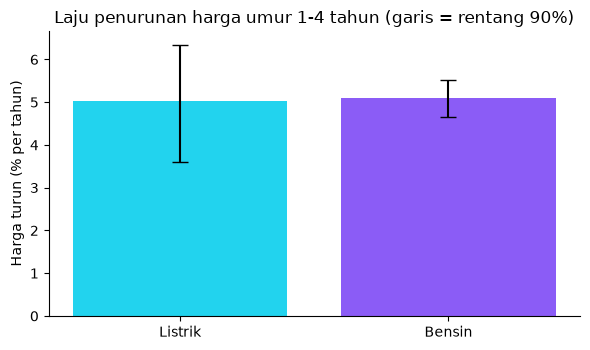

In [12]:
def laju_efek_tetap(d):
    d = d.copy()
    y = d["log_harga"] - d.groupby("model_lengkap")["log_harga"].transform("mean")
    x = d["umur"] - d.groupby("model_lengkap")["umur"].transform("mean")
    return (1 - np.exp((x * y).sum() / (x ** 2).sum())) * 100


w = pasar[pasar["umur"].between(1, 4)]
ev = w[w["bahan_bakar"] == "Listrik"]
ev = ev[ev["model_lengkap"].isin(ev["model_lengkap"].value_counts()[lambda s: s >= 25].index)]
bensin = w[w["bahan_bakar"] == "Bensin"]
bensin = bensin[bensin["model_lengkap"].isin(bensin["model_lengkap"].value_counts()[lambda s: s >= 100].index)]

hasil_ev, hasil_bensin = laju_efek_tetap(ev), laju_efek_tetap(bensin)

# ketidakpastian: bootstrap (ambil ulang sampel acak 300 kali)
rng = np.random.default_rng(0)
bs_ev = [laju_efek_tetap(ev.sample(len(ev), replace=True, random_state=int(rng.integers(1e9)))) for _ in range(300)]
bs_bensin = [laju_efek_tetap(bensin.sample(len(bensin), replace=True, random_state=int(rng.integers(1e9)))) for _ in range(300)]
ci_ev, ci_bensin = np.percentile(bs_ev, [5, 95]), np.percentile(bs_bensin, [5, 95])

print(f"Umur 1-4 tahun | mobil listrik: {len(ev)} iklan, {ev['model_lengkap'].nunique()} model | bensin: {len(bensin)} iklan, {bensin['model_lengkap'].nunique()} model")
print(f"Laju penurunan harga: LISTRIK {hasil_ev:.1f}% per tahun (rentang 90%: {ci_ev[0]:.1f}-{ci_ev[1]:.1f})  |  BENSIN {hasil_bensin:.1f}% (rentang 90%: {ci_bensin[0]:.1f}-{ci_bensin[1]:.1f})")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(["Listrik", "Bensin"], [hasil_ev, hasil_bensin], color=[CYAN, UNGU],
       yerr=[[hasil_ev - ci_ev[0], hasil_bensin - ci_bensin[0]], [ci_ev[1] - hasil_ev, ci_bensin[1] - hasil_bensin]], capsize=6)
ax.set_ylabel("Harga turun (% per tahun)")
ax.set_title("Laju penurunan harga umur 1-4 tahun (garis = rentang 90%)")
plt.tight_layout()
plt.show()

**Temuan:** pada umur 1-4 tahun, mobil **listrik turun ±5,0% per tahun** (rentang 90%: 3,6-6,3) dan **bensin ±5,1%** (4,7-5,5). **Tidak ada bukti bahwa mobil listrik bekas turun harga lebih cepat** pada 4 tahun pertama.

**Artinya:** kekhawatiran bahwa EV bekas "cepat anjlok" tidak terlihat di data iklan ini. Tetapi datanya hanya 6 model (BYD dan Wuling), umur maksimal 4 tahun, dan pasar EV masih muda, jadi kesimpulannya berlaku untuk periode itu saja.

## 7. Platform, waktu, dan sebaran harga

In [13]:
# --- platform: OLX (pembanding) vs Mobil123 vs Carsome, pada mobil bensin yang sama
p = df[df["model_lengkap"].isin(MODEL_POPULER) & (df["umur"] <= 15) & (df["bahan_bakar"] == "Bensin")].copy()
p["automatic"] = (p["transmisi"] == "Automatic").astype(float)
p["mobil123"] = (p["sumber"] == "Mobil123").astype(float)
p["carsome"] = (p["sumber"] == "Carsome").astype(float)
kp, _ = regresi(p, ["automatic", "mobil123", "carsome"])
print(f"Mobil123 vs OLX: {persen(kp['mobil123']):+.1f}%   |   Carsome (2023) vs OLX: {persen(kp['carsome']):+.1f}%   (model, umur, transmisi dikontrol)")

# --- waktu: batch 2026 vs batch 2025 (hanya data Zenodo)
z = pasar[pasar["batch"].notna() & pasar["model_lengkap"].isin(MODEL_POPULER) & (pasar["umur"] <= 15)].copy()
z["batch_2026"] = (z["batch"] == "B2-2026").astype(float)
kz, _ = regresi(z, ["batch_2026"])
print(f"Iklan batch 2026 vs batch 2025: {persen(kz['batch_2026']):+.1f}% (model dan umur dikontrol)")

# --- sebaran harga per merek: seberapa beragam harga untuk model dan umur yang sama
dd = pasar[pasar["model_lengkap"].isin(MODEL_POPULER) & (pasar["umur"] <= 15)].copy()
_, sisa = regresi(dd)
sebaran = (sisa.groupby(dd["merek"]).std() * 100).sort_values()
print("\nSebaran harga per merek (%), untuk model dan umur yang sama (makin besar = harga makin beragam):")
sebaran.round(1)

Mobil123 vs OLX: -0.4%   |   Carsome (2023) vs OLX: -6.2%   (model, umur, transmisi dikontrol)
Iklan batch 2026 vs batch 2025: +2.4% (model dan umur dikontrol)

Sebaran harga per merek (%), untuk model dan umur yang sama (makin besar = harga makin beragam):


merek
Suzuki          11.9
Mitsubishi      12.5
Honda           14.2
Daihatsu        14.8
Toyota          16.9
Mercedes-Benz   30.1
Name: log_harga, dtype: float64

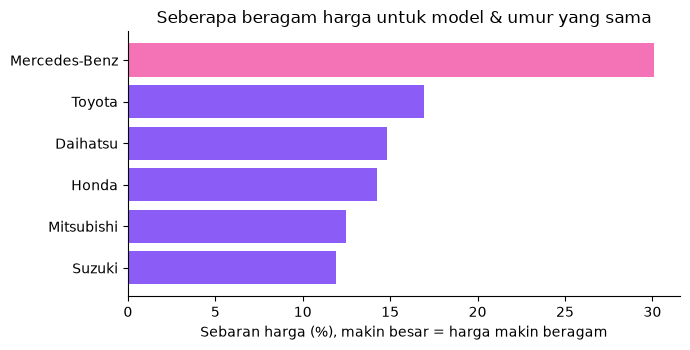

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(sebaran.index, sebaran.values, color=[PINK if m == "Mercedes-Benz" else UNGU for m in sebaran.index])
ax.set_xlabel("Sebaran harga (%), makin besar = harga makin beragam")
ax.set_title("Seberapa beragam harga untuk model & umur yang sama")
plt.tight_layout()
plt.show()

**Temuan:**
- **Mobil123 ≈ OLX** (selisih ±0,4%), jadi memilih platform tidak mengubah harga iklan secara berarti.
- **Carsome ±6% lebih rendah** daripada OLX untuk mobil, umur, dan transmisi yang sama. Tapi data Carsome dari 2023 dan penjualnya berbeda, jadi selisih ini bercampur antara efek platform dan efek waktu.
- **Iklan batch 2026 ±2-3% lebih tinggi** daripada batch 2025 (indikatif; komposisi hasil scraping bisa berbeda).
- **Sebaran harga Mercedes-Benz ±30%**, sekitar dua kali merek lain (±12-17%). Dua Mercedes C-Class dengan umur yang sama bisa berharga sangat berbeda (varian, kondisi, riwayat), dan inilah sebab Mercedes paling sulit ditebak oleh model.

**Artinya:** untuk mobil mewah, jangan pernah memakai satu angka; gunakan rentang dan rincian varian. Ini juga alasan app memberi rentang harga, bukan angka tunggal.

## 8. Ringkasan angka kunci

In [15]:
ringkasan = {
    "Penurunan harga umur 1 -> 5 tahun": f"{(1 - retensi[5]) * 100:.0f}%",
    "Penurunan harga umur 1 -> 10 tahun": f"{(1 - retensi[10]) * 100:.0f}%",
    "Laju penurunan median antar model": f"{laju['turun_%_per_tahun'].median():.1f}% per tahun",
    "Model paling tahan harga": f"{laju.iloc[0]['model']} ({laju.iloc[0]['turun_%_per_tahun']:.1f}% per tahun)",
    "Model paling cepat turun": f"{laju.iloc[-1]['model']} ({laju.iloc[-1]['turun_%_per_tahun']:.1f}% per tahun)",
    "Efek +10.000 km (umur sama)": f"{b_dengan_umur:+.1f}%",
    "Premium Automatic vs Manual": f"{prem_at:+.1f}%",
    "Laju turun listrik vs bensin (umur 1-4)": f"{hasil_ev:.1f}% vs {hasil_bensin:.1f}% per tahun",
    "Harga Mobil123 vs OLX": f"{persen(kp['mobil123']):+.1f}%",
}
pd.Series(ringkasan, name="angka kunci").to_frame()

,angka kunci
Penurunan harga umur 1 -> 5 tahun,24%
Penurunan harga umur 1 -> 10 tahun,48%
Laju penurunan median antar model,6.7% per tahun
Model paling tahan harga,Daihatsu Rocky (2.0% per tahun)
Model paling cepat turun,Mercedes-Benz GLE-Class (15.1% per tahun)
Efek +10.000 km (umur sama),-0.9%
Premium Automatic vs Manual,+7.2%
Laju turun listrik vs bensin (umur 1-4),5.0% vs 5.1% per tahun
Harga Mobil123 vs OLX,-0.4%


## 9. Ringkasan eksekutif

1. **Harga turun ±24% dalam 5 tahun pertama dan ±48% dalam 10 tahun.** Setelah umur 12, penurunan makin curam (11-14% per tahun).
2. **Merek menentukan seberapa cepat harga turun.** Mercedes-Benz ±12% per tahun, dua kali Toyota (±7%) dan tiga kali Daihatsu (±3,6%). Dalam rupiah, C-Class kehilangan ±Rp 69 juta per tahun vs Avanza ±Rp 12 juta.
3. **Umur jauh lebih penting daripada kilometer.** Setelah umur dikontrol, +10.000 km hanya menurunkan harga ±0,9%. Penalti baru terasa di atas ±80 rb km (±7%).
4. **Premium varian:** Automatic ±+7%, diesel ±+11% sampai +27% (Fortuner, Innova), hybrid penuh ±+25%, mild hybrid hanya ±+3%.
5. **Mobil listrik tidak lebih cepat turun** daripada bensin pada 4 tahun pertama (±5% per tahun, sama).
6. **Harga Mercedes jauh lebih beragam** (±30%) daripada merek lain (±12-17%), sehingga butuh rentang harga, bukan angka tunggal.

## 10. Rekomendasi

**Untuk penjual**
- Jual sebelum umur ±12 tahun, saat penurunan harga mulai melonjak.
- Jangan terlalu khawatir dengan kilometer menengah; penalti baru berarti di atas ±80 rb km, dan kilometer rendah hanya memberi bonus kecil (±2%).
- Cantumkan varian dengan tepat: Automatic, diesel, dan hybrid penuh menambah harga secara terukur.
- Untuk mobil mahal, gunakan rentang harga dan rincian kondisi, karena sebaran harganya lebar.

**Untuk pembeli**
- Umur 3-5 tahun adalah titik tengah yang masuk akal antara harga dan kondisi.
- Kalau ingin meminimalkan penyusutan, pilih model berlaju rendah (Sigra, Mobilio, Terios, Ayla, Brio). Biaya penyusutannya hanya ±Rp 4-7 juta per tahun pada umur 5 tahun.
- Bandingkan harga dengan rentang model pada umur yang sama, bukan dengan kilometer saja.
- EV bekas tidak terbukti kehilangan harga lebih cepat daripada bensin pada 4 tahun pertama.

## 11. Keterbatasan
- **Harga iklan, bukan harga transaksi**, dan hanya sebagian besar dari Jabodetabek.
- **Potret satu waktu (2025-2026):** membandingkan mobil umur berbeda, bukan melacak satu mobil. Mobil lama juga bisa berbeda generasi dan spesifikasi.
- **Bias seleksi:** mobil yang masih diiklankan pada umur tua mungkin bukan representatif semua mobil seumur itu.
- **Kilometer kasar dan sering kosong** (OLX ±69% kosong, berbentuk rentang).
- **Mobil listrik** baru, hanya 6 model dan umur ≤ 4 tahun.
- **Ini asosiasi, bukan sebab-akibat.** Misalnya premium diesel bercampur dengan perbedaan trim.
- Carsome (2023) dan marketplace (2025-2026) dibandingkan dengan keterbatasan waktu yang berbeda.